# 🌲 Regularization, Qərar ağacları və Boosting
### Modul 3 · Dərs 2 · Supervised Learning alqoritmləri

Keçən dərsdə bir düstur öyrətdik: `qiymət = w × sahə + b`. Modelin yaxşı olub-olmadığını **MAE**, **MSE** və **R²** ilə ölçdük.

Bu gün sual dəyişir. Keçən dərsdə model həmişə düz xətt idi. Bəs model köhnə mənzilləri əzbərləsə? Bəs qiymət düz xətt deyilsə?

Bu dərsdə:

1. **Overfitting** nədir: model köhnə datanı əzbərləyəndə nə baş verir
2. **Train** və **test**: köhnə suallar və yeni suallar
3. **Regularization**, **Ridge (L2)** və **Lasso (L1)**: böyük `w`-ləri necə dayandırırıq
4. **Decision Tree** və **entropy**
5. Housing prices: ağacı özümüz oxuyuruq
6. **Random Forest**
7. **Gradient Boosting** və **XGBoost**


## 🗺️ Bu gün nə edəcəyik?

| Addım | Mövzu | Vaxt |
|---|---|---|
| 1 | Overfitting, train və test | 15 dəq |
| 2 | Regularization: Ridge (L2) və Lasso (L1) | 25 dəq |
| 3 | Decision Tree və entropy | 25 dəq |
| 4 | Housing prices üzərində ağac | 15 dəq |
| 5 | Random Forest | 15 dəq |
| 6 | Gradient Boosting və XGBoost | 20 dəq |
| 7 | Müqayisə + tapşırıq (1-3 dərsdə, 4-7 evdə) | 15 dəq |

> Dərs uzundur. Hər modelin bir qrafikini və bir cədvəlini birlikdə oxuyacağıq. Rəqəmi görmədən fikir havada qalır.


# 🅰️ Hissə 1. Regularization

## 1️⃣ Overfitting nədir?

Keçən dərsdə model bir şey istəyirdi: error mümkün qədər kiçik olsun. Xətt nöqtələrə mümkün qədər yaxın keçsin.

Bu həmişə yaxşı məqsəd deyil. Əvvəl insanla baxaq, sonra eyni şeyi modeldə görək.

### Tələbə və imtahan

Keçən ilin imtahanında 3 sual var idi:

| Sual | Düzgün cavab |
|---|---|
| 50 kv.m mənzil neçəyədir? | 100 min AZN |
| 80 kv.m mənzil neçəyədir? | 160 min AZN |
| 110 kv.m mənzil neçəyədir? | 210 min AZN |

**Tələbə A qaydanı öyrənir.** "Hər kv.m təxminən 2 min AZN-dir." Yeni imtahanda 70 kv.m soruşsalar, 140 deyir. Tam köhnə cavab deyil, amma qaydaya uyğundur.

**Tələbə B yalnız bu 3 cavabı əzbərləyir.** Eyni imtahanı yenidən versələr, 100 bal alır: suallar eynidir, cavablar yadındadır. Yeni imtahanda 70 kv.m gələndə isə durur. 50, 80 və 110-u bilir, 70 yadındadır. Ya heç nə yazmır, ya da təsadüfi rəqəm yazır.

Tələbə B pis oxumayıb. O, **başqa şeyi** öyrənib: qaydanı yox, köhnə vərəqin cavablarını.

### Model də bunu edə bilər

Modelə 11 mənzil veririk. Əsl qayda sadədir: sahə artır, qiymət də düz xətt kimi artır.

Hər real qiymətdə kiçik təsadüfi fərq var. Buna **noise** deyirik. Məsələn, qayda 100 deyir, elanda 103 və ya 97 yazılıb. Kiməsə endirim olub, kiminsə qiyməti yuvarlaqlaşıb. Bu fərq qayda deyil.

İki model düşünək:

- **Sadə model** bir düz xətt çəkir. Heç bir nöqtənin tam üstündən keçmir, çünki 103 ilə 97-ni qovmur. Yeni mənzil üçün ağlabatan qiymət deyir. Bu, Tələbə A-dır.
- **Çox çevik model** elə əyri çəkir ki, köhnə 11 nöqtənin hamısının üstündən keçsin. Köhnə mənzillərdə error **0** olur. Amma əyri noise-u da yadda saxlayıb. İki köhnə nöqtənin arasında xətt yuxarı-aşağı gedir. Oraya düşən yeni mənzil üçün qəribə qiymət çıxır: qonşuları 100 və 110-dursa, model 40 və ya 200 deyə bilər. Bu, Tələbə B-dir.

Buna **overfitting** deyilir.

> **Overfitting** = model köhnə data-nı əzbərləyir, ümumi qaydanı öyrənmir. Köhnə suallarda error kiçikdir. Yeni suallarda error böyükdür.

Bir cümlə ilə: train-də əla, test-də pisdirsə, bu overfitting-dir. Train və test-i növbəti hissədə ayıracağıq, sonra həmin əyri xətti gözlə görəcəyik.


## 2️⃣ Train və Test

Tələbə B-ni yalnız köhnə imtahanla yoxlasaq, o dahi görünər. Onu yeni suallarla yoxlamaq lazımdır.

Data-nı da iki yerə bölürük:

| Hissə | Nədir? | İmtahan dili ilə |
|---|---|---|
| **Train** | Modelin gördüyü sətirlər. `fit` bunu öyrənir | Köhnə imtahan, ev tapşırığı |
| **Test** | Modelin görmədiyi sətirlər. Burada yalnız `predict` edirik | Yeni imtahan |

400 mənzil olsa, məsələn 300-ü train, 100-ü test olur. Test mənzillərinin qiymətini model öyrənərkən görmür.

> 💡 **Qayda:** "model yaxşıdır" demək üçün train MAE-yə baxmaq olmaz. Qərarı **test MAE** və **test R²** verir.

Overfitting-in əlaməti budur: train MAE çox kiçikdir, test MAE isə böyükdür. Əvvəl bunu 11 nöqtəlik şəkildə görək. Sonra 400 mənzillik Housing cədvəlinə keçəcəyik.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["font.size"] = 12

### 11 nöqtə: əzbərləyən xətt və sakit xətt

Şəkildə 11 nöqtə var. Əsl qayda demək olar ki, düz xəttdir: `y ≈ 0.2 + 0.8x`. Üstünə kiçik noise əlavə olunub, ona görə nöqtələr xəttin bir az altında və üstündədir.

`x` burada şərti rəqəmdir, manat deyil. Məqsəd qiymət yox, **xəttin formasını** görməkdir. `x`-i kiçik saxlayırıq ki, `x¹⁰` nəhəng olub kompüteri çaşdırmasın.

Üç model öyrədəcəyik:

| Model | Nə edir? | Neçə w var? |
|---|---|---|
| Düz xətt, dərəcə 1 | Keçən dərs: `y = w·x + b` | 1 w və 1 b |
| Dərəcə 10 | `x, x², x³, ... x¹⁰` istifadə edir. 11 nöqtəni nöqtə-nöqtə tuta bilir | 10 w |
| Yenə dərəcə 10, amma Ridge | Eyni 10 w, amma böyük w-lərə cərimə yazılır | 10 w, cəriməli |

Dərəcə 10 o deməkdir ki, modelə çox sərbəstlik veririk. O, düz xətt çəkməyə məcbur deyil. İstəsə, hər nöqtədən keçən əyri çəkə bilər.


In [1]:
rng = np.random.default_rng(1)
x = np.linspace(-1, 1, 11)
y_toy = 0.2 + 0.8 * x + rng.normal(0, 0.12, size=len(x))
X_toy = x.reshape(-1, 1)

# x, x^2, ..., x^10 sütunları
poly = PolynomialFeatures(degree=10, include_bias=False)
X10 = poly.fit_transform(X_toy)

duz = LinearRegression().fit(X_toy, y_toy)
ezber = LinearRegression().fit(X10, y_toy)
sakit = Ridge(alpha=1).fit(X10, y_toy)

xx = np.linspace(-1.25, 1.25, 400).reshape(-1, 1)
xx10 = poly.transform(xx)

print(f"Düz xətt    train MAE = {mean_absolute_error(y_toy, duz.predict(X_toy)):.3f}")
print(f"Dərəcə 10   train MAE = {mean_absolute_error(y_toy, ezber.predict(X10)):.3f}")
print(f"Ridge       train MAE = {mean_absolute_error(y_toy, sakit.predict(X10)):.3f}")

NameError: name 'np' is not defined

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

for ax, limit, basliq in [
    (axes[0], (-1.6, 1.8), "Nöqtələrin içində: əzbər xətt əyilir"),
    (axes[1], (-20, 40), "Kənarda: əzbər xətt uçur"),
]:
    ax.scatter(x, y_toy, s=70, color="black", zorder=3, label="Nöqtələr")
    ax.plot(xx, duz.predict(xx), color="blue", linewidth=2.5, label="Düz xətt")
    ax.plot(xx, ezber.predict(xx10), color="red", linewidth=2, label="Dərəcə 10")
    ax.plot(xx, sakit.predict(xx10), color="green", linewidth=2.5, label="Ridge")
    ax.set_ylim(*limit)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(basliq)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 👀 Qrafikdən nə görürük?

Sol şəkil nöqtələrin içinə zoom edib. Sağ şəkil kənarı da göstərir.

**Qırmızı xətt, dərəcə 10.** Train MAE = **0**. Yəni köhnə 11 nöqtənin hamısının üstündən keçir, Tələbə B kimi. Sol şəkildə nöqtələrin arasında dalğalanır: bir az yuxarı, bir az aşağı. Sağ şəkildə, data-nın kənarında, yuxarı və aşağı uçur. Yeni `x` bir az kənara düşsə, prediction absurddur. Bu, overfitting-dir.

**Mavi düz xətt.** Train MAE sıfır deyil, təxminən 0.05. Bəzi nöqtələrin bir az yanından keçir, çünki noise-u qovmur. Həm solda, həm sağda sakit qalır. Yeni `x` üçün bu xəttə etibar etmək olar. Bu, Tələbə A-dır.

**Yaşıl Ridge.** O da 10 ədəd w istifadə edir, qırmızı xətt kimi. Amma böyük w-lərə icazə vermir, ona görə dalğa və uçuş yoxdur. Train MAE təxminən 0.10-dur, hətta düz xətdən bir az böyük. Bu, problem deyil. Biz köhnə 11 nöqtəni mükəmməl tutmaq yox, yeni nöqtədə ağlabatan cavab istəyirik.

**Sual:** train MAE-si 0 olan model niyə ən yaxşısı deyil?

Çünki bizim işimiz köhnə nöqtələri təkrar demək deyil. Yeni mənzilin qiymətini deməkdir. Qırmızı xətt köhnədə mükəmməldir, yenidə isə ən təhlükəlisidir.


## 3️⃣ Regularization nədir?

Qırmızı xətt niyə bu qədər əyildi? Çünki `w`-ləri çox böyük oldu. Böyük `w` xətti kəskin dartır: kiçik bir `x` dəyişəndə `y` çox tullanır.

Keçən dərsdə model yalnız bunu kiçildirdi:

> **Cost = MSE**

İndi ikinci istək əlavə edirik: `w`-lər böyük olmasın.

> **Yeni Cost = MSE + alpha × cərimə(w)**

| Hissə | Nə soruşur? |
|---|---|
| **MSE** | Köhnə nöqtələrə nə qədər yaxınam? |
| **cərimə(w)** | `w`-lər nə qədər böyükdür? |
| **alpha** | Bu cəriməyə nə qədər əhəmiyyət veririk? |

Üç hal:

- **alpha = 0.** Cərimə yoxdur. Bu, adi Linear Regression-dur. Qırmızı xətt buradan çıxır.
- **alpha kiçikdir.** Model nöqtələrə yaxın durur, amma ən vəhşi əyrilər bir az kəsilir.
- **alpha çox böyükdür.** Model `w`-ləri sıfıra yaxın saxlayır. Xətt o qədər sadələşir ki, artıq əsl qaydanı da tuta bilmir. Buna **underfitting** deyilir: model həm train-də, həm test-də zəifdir. Overfitting-in əksi.

Underfitting-i də tələbə ilə tutaq. İmtahana heç oxumayan tələbə köhnə vərəqdə də, yeni vərəqdə də pis yazır. Əzbərləyən tələbə yalnız köhnədə yaxşı yazır. Biz ortadakını istəyirik: qaydanı öyrənən.

`b` (bias) adətən cərimələnmir. Cərimə yalnız `w`-lərə aiddir. Başlanğıc qiymət böyük ola bilər. Problem ondadır ki, hər kv.m üçün nəhəng əmsal yazanda xətt kiçik bir dəyişiklikdə çox tullanır.

İki məşhur cərimə var:

| Ad | Cərimə nədir? | Cost |
|---|---|---|
| **Ridge, L2** | `w`-lərin kvadratlarının cəmi | MSE + alpha × (w₁² + w₂² + ...) |
| **Lasso, L1** | `w`-lərin modullarının cəmi | MSE + alpha × (abs(w₁) + abs(w₂) + ...) |


### L1 və L2-nin forması niyə vacibdir?

Hər iki cərimə böyük `w`-ni sevmir. Fərq **0-ın yanında** görünür. Bir ədəd `w` üçün cəriməni çəkək.


In [ ]:
w = np.linspace(-2, 2, 400)

plt.plot(w, w ** 2, color="green", linewidth=2.5, label="L2: w²  (Ridge)")
plt.plot(w, np.abs(w), color="purple", linewidth=2.5, label="L1: |w|  (Lasso)")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("w")
plt.ylabel("Cərimə")
plt.title("0-ın yanında L1 iti, L2 yumşaqdır")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 🔑 Bu forma modeli nəyə məcbur edir?

**L2, yaşıl parabola.** 0-ın yanında yumşaqdır. `w = 0.2` olanda cərimə `0.04`-dür, demək olar ki, pulsuz. Ona görə Ridge kiçik `w`-ni saxlayır. Yalnız həqiqətən böyük `w`-ləri əzir. Heç bir `w` mütləq 0 olmur.

**L1, bənövşəyi V.** 0-da iti künc var. `w = 0.2` olanda cərimə artıq `0.2`-dir. Kiçik `w` də pul ödəyir. Model tez-tez belə qərar verir: "bu sütun az kömək edirsə, `w`-ni tam 0 yazım, cərimədən qurtarım."

Eyni fikri sözlə:

- **Ridge:** "Hamınız cavab verə bilərsiniz, amma qışqırmayın." Bütün sütunlar qalır, əmsallar kiçilir.
- **Lasso:** "Əmin deyilsənsə, sus." Susmaq = `w = 0`. Lazımsız sütun modeldən düşür. Buna **feature selection** deyilir.

> 💡 Ridge `w`-ləri kiçildir. Lasso bəzilərini **tam 0** edir.


## 4️⃣ Housing prices

İndi 11 nöqtəni qoyuruq, 400 mənzilə keçirik. Qiymət min AZN-dir.

Fayl notebook ilə eyni qovluqda olmalıdır: `housing_prices_ders2.csv`.

Bu, klassik Housing prices tapşırığıdır: mənzilin əlamətlərindən qiymətini tapmaq. Rəqəmlər dərs üçündür, real elan saytı deyil. İçində real bir çətinlik var: qiymət hər yerdə eyni düz xətlə getmir. Mərkəzdə bir qayda, kənarda başqa qayda var.


In [ ]:
df = pd.read_csv("housing_prices_ders2.csv")

for sutun in ["otaq", "mertebe", "balkon"]:
    df[sutun] = df[sutun].astype(int)

df.head(8)

In [ ]:
df.describe().round(2)

| Sütun | Nədir? |
|---|---|
| `sahe` | Sahə, kv.m |
| `otaq` | Otaq sayı |
| `yas` | Binanın yaşı, il |
| `merkez_km` | Şəhər mərkəzinə qədər məsafə, km |
| `mertebe` | Mərtəbə |
| `balkon` | Balkon var (1) və ya yoxdur (0) |
| `gurultu_1`, `gurultu_2` | Noise sütunları. Başqa sistemdən düşmüş rəqəmlərdir. Qiymətə kömək edib-etmədiyini hələ bilmirik |
| `qiymet` | Target, min AZN. Bunu proqnozlaşdırırıq |

Keçən dərsdə bir feature var idi: sahə. İndi 8 feature var, deməli model 8 ədəd `w` öyrənəcək. Sualımız budur: 8-nin hamısı lazımdırmı, yoxsa bəziləri yalnız noise-dur?


In [ ]:
plt.scatter(df["sahe"], df["qiymet"], s=18, alpha=0.7, c=df["merkez_km"], cmap="viridis")
plt.colorbar(label="Mərkəzə məsafə (km)")
plt.xlabel("Sahə (kv.m)")
plt.ylabel("Qiymət (min AZN)")
plt.title("Eyni sahə, fərqli qiymət: rəng = mərkəzə məsafə")
plt.grid(alpha=0.3)
plt.show()

Nöqtələr bir xəttin üstünə yığılmır. Eyni sahədə həm 100 minlik, həm 250 minlik mənzil var.

Rəngə baxın. Bənövşəyi nöqtələr mərkəzə yaxındır (təxminən 2 km) və yuxarıdadır, yəni bahadır. Sarı nöqtələr uzaqdadır (10–14 km) və aşağıdadır, yəni ucuzdur. 100 kv.m-lik mənzil mərkəzdə 250 min, kənarda 120 min ola bilər.

Bir düz xətt bütün nöqtələrə bir düstur yazır. O, mərkəzdə bir qiymət, kənarda başqa qiymət fərqini tam tuta bilmir. İndi xətti modeli və onun cəriməsini yoxlayaq.


## 5️⃣ Verilənləri bölək

400 sətirin 75%-i train (300 mənzil), 25%-i test (100 mənzil). `random_state=42` bölgünü sabit saxlayır. Sinifdə hamıda eyni 300 və eyni 100 çıxır, rəqəmləri müqayisə etmək olur.


In [16]:
features = ["sahe", "otaq", "yas", "merkez_km", "mertebe", "balkon", "gurultu_1", "gurultu_2"]
X = df[features]
y = df["qiymet"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print("Train:", len(X_train), "  Test:", len(X_test))

Train: 300   Test: 100


### Niyə sütunları eyni miqyasa gətiririk?

Cərimə `w`-nin hansı sütundan gəldiyini bilmir. O, yalnız rəqəmə baxır. Rəqəm böyükdürsə, cərimə də böyükdür.

Scaler-dən əvvəl belə iki `w` çıxa bilər:

- `sahe` üçün `w = 1.2`. Sahə **1 kv.m** artanda qiymət **1.2 min AZN** artır. Sahə 30 kv.m artanda artım `30 × 1.2 = 36` min AZN olur.
- `balkon` üçün `w = 11`. Balkon yoxdursa sütun 0-dır, varsa 1-dir. Qiymət **11 min AZN** artır. Burada addım 1 kv.m deyil. Addım "balkon var, ya yoxdur".

Pula baxsaq, sahə daha çox iş görür: 30 kv.m üçün 36 min, balkon üçün 11 min. Cərimə pula baxmır. Cərimə `11` və `1.2` rəqəmlərinə baxır. `11` daha böyükdür, ona görə balkon daha ağır cərimə alır.

Balkonun `w`-si ona görə böyük rəqəm olur ki, balkon sütunu yalnız 0 və 1-dir. 11 min AZN almaq üçün `w` özü 11 olmalıdır. Sahə isə 40, 80, 120 kimi böyük rəqəmlərlə yazılır. Hər kv.m üçün kiçik `w` kifayət edir, çünki kv.m-in özü onsuz da böyükdür. Vahid fərqli olanda bu iki `w`-ni bir-biri ilə tutuşdurmaq olmur.

İndi eyni iki `w` üzərində Ridge və Lasso cəriməsini ayrıca yazaq. `alpha = 1` götürürük ki, formul görünsün. `alpha` başqa rəqəm olanda hər iki cərimə həmin rəqəmə vurulur.

**Ridge (L2)** hər `w`-ni kvadrata yüksəldir və toplayır.

- sahə: `1.2² = 1.44`
- balkon: `11² = 121`
- cəm: `1.44 + 121 = 122.44`

Cost-a əlavə olan hissə: `alpha × 122.44`. Bunun demək olar ki, hamısı balkondan gəlir. `121`, `1.44`-dən təxminən **84 dəfə** böyükdür. Kvadrat böyük ədədi çox böyüdür, kiçik ədədi isə daha da kiçik edir. Ridge sahənin `w`-sini az tərpədir, balkonun `w`-sini isə güclü kiçildir. İkisini də saxlayır. Heç birini tam 0 etmir.

**Lasso (L1)** hər `w`-nin modulunu götürür. Modul mənfi işarəni atır: `|−11| = 11`, `|11| = 11`.

- sahə: `|1.2| = 1.2`
- balkon: `|11| = 11`
- cəm: `1.2 + 11 = 12.2`

Cost-a əlavə olan hissə: `alpha × 12.2`. Balkonun payı burada da böyükdür, amma fərq 84 dəfə deyil. `11 / 1.2 ≈ 9`, yəni təxminən **9 dəfə**. Lasso hər 1 vahid `w` üçün eyni cərimə yazır. `w` 11-dirsə cərimə 11-dir. `w`-ni 0 etsən, cərimə də 0 olur. Ona görə Lasso tez-tez belə edir: sütun az kömək edirsə, onun `w`-sini tam 0 yazır və o sütunu modeldən çıxarır. Bu nümunədə balkonun cəriməsi 11-dir. Model bu 11-i balkonun verdiyi köməkdən baha saysa, `w = 0` yazır. Ridge eyni yerdə `w`-ni kiçildir, amma 0 yazmır.

| | sahə, `w = 1.2` | balkon, `w = 11` | nə baş verir |
|---|---|---|---|
| Ridge, `w²` | 1.44 | 121 | ikisini də kiçildir. 11 çox kiçilir, 1.2 az kiçilir. Heç biri tam 0 olmur |
| Lasso, `abs(w)` | 1.2 | 11 | cəriməni 0 etmək üçün zəif sütunun `w`-sini tam 0 yaza bilir |

**StandardScaler** sütunları eyni miqyasa gətirir. İki addım var.

1. Ortadan çıxırıq. Sahənin ortası 84 kv.m-dirsə, 84 kv.m olan mənzil 0 olur. 94 kv.m olan mənzil `+10` olur.
2. Bu fərqi **standard deviation**-a bölürük.

**Standard deviation** sütunun rəqəmləri ortadan nə qədər uzağa yayılıb, onu göstərir. Kiçikdirsə, rəqəmlərin çoxu ortaya yaxındır. Böyükdürsə, ortadan uzaq rəqəmlər də var. Sahə üçün standard deviation təxminən 31 kv.m-dir. Yəni sahə ortadan adətən təxminən 31 kv.m kənara çıxır. Çox mənzil `84 − 31 = 53` kv.m ilə `84 + 31 = 115` kv.m arasındadır. Hamısı bu aralıqda deyil. Bu, adi yayılmadır.

Böldükdən sonra `1` artıq 1 kv.m demək deyil. `1` deməkdir: sütun öz ortasından **1 standard deviation** uzaqdır. Sahədə bu, təxminən 31 kv.m-dir. Balkonda sütun 0 və 1 olduğu üçün 1 standard deviation başqa, kiçik bir rəqəmdir. İndi hər iki sütunda bir addım eyni şeydir: ortadan bir standard deviation.

Yeni `w` belə oxunur:

> `w = 30` o deməkdir: sütun **1 standard deviation** artanda qiymət 30 min AZN dəyişir.

Sahənin `w`-si 30-dursa, sahə ortadan təxminən 31 kv.m artanda (84-dən 115-ə) model qiymətə təxminən 30 min AZN əlavə edir. Eyni `w = 30` balkonda olsaydı, bu da "balkon 1 standard deviation dəyişəndə 30 min" olardı. İndi 30 ilə 30-u müqayisə etmək olar. Scaler-dən əvvəl 1.2 ilə 11-i müqayisə etmək olmazdı: biri kv.m üçün idi, o biri isə 0 və 1 üçün.

Scaler-i yalnız train üzərində `fit` edirik. Train-in ortasını və standard deviation-ını saxlayırıq. Testə də elə həmin rəqəmləri tətbiq edirik. Testin öz ortasını və öz standard deviation-ını hesablamırıq. Test yeni data-dır. Onun rəqəmlərindən orta çıxarmaq, testə baxıb öyrənmək deməkdir.


In [17]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=features)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=features)

print(f"Train-də sahənin ortası : {scaler.mean_[0]:.1f} kv.m")
print(f"Train-də sahənin std-si : {scaler.scale_[0]:.1f} kv.m")
X_train_s.head(3).round(2)

Train-də sahənin ortası : 83.6 kv.m
Train-də sahənin std-si : 30.8 kv.m


,sahe,otaq,yas,merkez_km,mertebe,balkon,gurultu_1,gurultu_2
0,-0.04,0.44,1.28,-1.11,-1.52,0.97,0.45,0.13
1,-0.74,-0.46,0.59,-1.44,1.60,0.97,0.88,-1.15
2,0.71,0.44,0.11,0.31,-1.52,0.97,0.35,-0.50


### Scaler-i unutsaq nə olur?

Eyni `alpha = 2`, amma sütunlar hələ kv.m, km və 0/1 kimidir. Aşağıdakı `w`-lərə baxın. Sonra eyni alpha-nı miqyaslanmış datada yenidən görəcəyik.


In [18]:
lasso_xam = Lasso(alpha=2, max_iter=20000)
lasso_xam.fit(X_train, y_train)

pd.Series(lasso_xam.coef_, index=features).round(3).rename("w, miqyaslanmamış")

sahe          1.269
otaq          0.000
yas          -0.746
merkez_km   -11.908
mertebe       0.421
balkon        3.293
gurultu_1     0.000
gurultu_2    -0.000
Name: w, miqyaslanmamış, dtype: float64

`otaq` sütununun `w`-si **0** oldu. Halbuki otaq sayı qiymətə təsir edir, onu atmaq düzgün deyil.

Səbəb yuxarıdakı 1.2 ilə 11 nümunəsidir. Sahənin `w`-si təxminən 1.3-dür (hər kv.m üçün). Otağın `w`-si isə bir neçə vahiddir (hər otaq üçün). Lasso bu rəqəmləri eyni cərimədə görür və daha böyük görünən `w`-ni, yəni otağı, sıfırlayır. Pul effektinə yox, əmsalın öz böyüklüyünə baxır.

Aşağıda eyni `alpha = 2` miqyaslanmış datadadır. Orada `otaq` qalır. Sıfırlananlar isə `gurultu_1` və `gurultu_2` olur, yəni noise sütunları.


## 6️⃣ Linear, Ridge və Lasso yan-yana

Üç model, eyni 300 train mənzili, eyni 100 test mənzili. Hamısı miqyaslanmış sütunları görür.

- Linear: cərimə yoxdur, alpha = 0 kimi
- Ridge: `alpha = 10`
- Lasso: `alpha = 2`

Bu alpha-ları bir azdan dəyişəcəyik. İndi əvvəl `w` cədvəlini oxumağı öyrənək.


In [19]:
def qiymetlendir(ad, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    p_tr = model.predict(X_tr)
    p_te = model.predict(X_te)
    setir = {
        "train MAE": mean_absolute_error(y_train, p_tr),
        "test MAE": mean_absolute_error(y_test, p_te),
        "train R²": r2_score(y_train, p_tr),
        "test R²": r2_score(y_test, p_te),
    }
    print(f"{ad:18} test MAE = {setir['test MAE']:.2f}   test R² = {setir['test R²']:.3f}")
    return model, setir

linear, s_lin = qiymetlendir("Linear", LinearRegression(), X_train_s, X_test_s)
ridge, s_ridge = qiymetlendir("Ridge", Ridge(alpha=10), X_train_s, X_test_s)
lasso, s_lasso = qiymetlendir("Lasso", Lasso(alpha=2, max_iter=20000), X_train_s, X_test_s)

cedvel_w = pd.DataFrame({
    "Linear": linear.coef_,
    "Ridge L2": ridge.coef_,
    "Lasso L1": lasso.coef_,
}, index=features).round(2)
cedvel_w

Linear             test MAE = 21.92   test R² = 0.827
Ridge              test MAE = 21.82   test R² = 0.828
Lasso              test MAE = 22.19   test R² = 0.826


,Linear,Ridge L2,Lasso L1
sahe,36.23,33.10,35.32
otaq,3.64,6.00,2.13
yas,-8.50,-8.41,-6.74
merkez_km,-49.81,-48.05,-48.22
mertebe,2.41,2.50,0.57
balkon,5.70,5.74,3.81
gurultu_1,1.19,1.25,0.00
gurultu_2,0.33,0.19,0.00


### Cədvəli necə oxuyuruq?

Bu `w`-lər artıq "1 kv.m" demək deyil. "1 standard deviation" deməkdir. İşarə istiqamətdir:

- **sahe** müsbətdir. Sahə artanda qiymət artır.
- **yas** mənfidir. Bina köhnəldikcə qiymət düşür.
- **merkez_km** mənfidir və böyükdür. Mərkəzdən uzaqlaşdıqca qiymət aydın şəkildə düşür. Qrafikdəki bənövşəyi/sarı fərqi buradadır.

İndi `gurultu_1` və `gurultu_2` sətirlərinə baxın. Bunlar noise sütunlarıdır, qiymətin əsl qaydasına girmirlər.

- **Linear** onlara kiçik, amma 0 olmayan `w` yazır. Model noise-u da bir az "izah etməyə" çalışır. Bu, overfitting-in kiçik formasıdır: təsadüfi sütunu da yadda saxlayır.
- **Ridge** onları 0 etmir. Kiçik `w` saxlayır. Sahə ilə otaq bir-birinə bağlıdır (böyük mənzildə adətən çox otaq olur). Ridge bu iki sütunun çəkisini aralarında bölüşdürür, ona görə bəzi `w`-lər hətta bir az böyüyə bilər. Bu, kod xətası deyil.
- **Lasso** hər iki noise sütununun `w`-sini **tam 0** edir. "Bu sütunlar susun" deyir. `otaq` isə bu dəfə 0 olmur, çünki scaler-dən sonra əmsallar müqayisə oluna bilir.

Test MAE üç modeldə də təxminən **22 min AZN**-dir. Lasso burada möcüzə yaratmır: test bir az da yaxşılaşmır.

Bu, vacib nəticədir.

> Regularization artıq sütunu təmizləyir. O, əyri qaydanı düz xəttə çevirmir.

Qrafikdə gördük ki, mərkəz və kənar eyni xətt deyil. Bunu bir azdan ağac tutacaq. Lasso-nun faydası başqadır: modelin izahı təmiz olur. "Qiymət bu sütunlardan asılıdır, bu ikisindən yox" deyə bilirik.


### alpha böyüyəndə nə olur?

Lasso-nun alpha-sı böyüdükcə daha çox sütun 0 olur. Əvvəl noise gedir. Alpha həddindən böyük olanda faydalı sütunlar da gedir və test pisləşir. Bu, underfitting-dir: model artıq qaydanı da atır.


In [20]:
setirler = []
for alpha in [0.5, 2, 8, 30]:
    model = Lasso(alpha=alpha, max_iter=20000)
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    sifir = int(np.sum(np.abs(model.coef_) < 1e-8))
    setirler.append({
        "alpha": alpha,
        "sıfır olan w": sifir,
        "test MAE": round(mean_absolute_error(y_test, pred), 2),
        "test R²": round(r2_score(y_test, pred), 3),
    })
pd.DataFrame(setirler)

,alpha,sıfır olan w,test MAE,test R²
0,0.5,1,22.01,0.827
1,2.0,2,22.19,0.826
2,8.0,5,24.18,0.793
3,30.0,6,40.25,0.450


| alpha | Nə olur? |
|---|---|
| **0.5** | Yalnız bir noise sütunu 0 olur |
| **2** | Hər iki noise sütunu 0 olur, sahə, məsafə, yaş, otaq qalır. Bizim seçimimiz |
| **8** | Otaq, mərtəbə və balkon da 0 olur. Test MAE artır |
| **30** | Demək olar ki, yalnız sahə və məsafə qalır. Test MAE təxminən 40-a çıxır, R² təxminən 0.45 olur. Model çox sadələşib |

**Sual:** alpha-nı mümkün qədər böyük seçmək niyə pisdir?

Çünki cərimə MSE-dən güclü olur. Model "heç bir sütuna əmsal yazmayaq, cərimə 0 olsun" deyir. Error böyüyür, həm train-də, həm test-də. Bu, underfitting-dir.

Praktikada bir neçə alpha yoxlanılır və **test** metrikası ən yaxşı olan seçilir. Böyük layihədə bunu cross-validation avtomat edir. Bu gün əl ilə görmək kifayətdir: alpha 2 təmizdir, alpha 30 artıq qaydanı da silir.


# 🅱️ Hissə 2. Qərar ağacı

## 7️⃣ Ağac nə edir?

Linear Regression bütün mənzillərə bir düstur yazır. 400 evin hamısı eyni `w` və `b`-ni bölüşür.

**Decision Tree** düstur yazmır. Sual verir, mənzilləri iki qrupa bölür, sonra hər qrupa təzə sual verir.

Həkim də belə işləyir. "Hərarətin var?" Bəli olanlar bir tərəfə, xeyr olanlar o biri tərəfə. Sonra hər qrupa növbəti sual. Sonda qısa bir nəticə.

Housing üçün suallar belə ola bilər:

```
Mərkəzə məsafə 4.4 km-dən azdırmı?
├── bəli → Sahə 93 kv.m-dən kiçikdirmi?
│          ├── bəli → bu qrupun orta qiyməti
│          └── xeyr → bu qrupun orta qiyməti
└── xeyr → Sahə 85 kv.m-dən kiçikdirmi?
           ├── bəli → ...
           └── xeyr → ...
```

Sonda düşdüyünüz qutuya **leaf** (yarpaq) deyilir. Regression-da leaf-in cavabı o qutudakı train mənzillərinin orta qiymətidir. Yeni mənzil həmin qutuya düşürsə, model ona bu ortanı deyir.

Fərq budur: xətt hər evə eyni düsturu tətbiq edir. Ağac deyir: "əvvəl rayonunu soruş, sonra sahəni." Mərkəzdəki 90 kv.m ilə kənardakı 90 kv.m eyni cavabı almır.


## 8️⃣ Alqoritm, addım-addım

Ağac `w` axtarmır. O, ən yaxşı sualı axtarır.

1. Əvvəl bütün train mənzilləri bir yerdədir. Buna kök deyilir.
2. Model çoxlu sual yoxlayır. "Sahə 50-dən böyükdür?", "Sahə 80-dən böyükdür?", "Məsafə 4 km-dən azdır?", "Yaş 10-dan böyükdür?" Hər sütun, çoxlu sərhəd.
3. Elə sualı seçir ki, alınan iki qrup daha təmiz olsun. Təmiz qrup o deməkdir ki, içinə düşən mənzillər bir-birinə bənzəyir.
4. Hər qrup üçün 2-ci və 3-cü addım təkrarlanır.
5. Dayanırıq, əgər:
   - qrup artıq təmizdir, və ya
   - qrupda çox az mənzil qalıb, və ya
   - `max_depth` limitinə çatdıq. Məsələn, ən çoxu 3 sual.
6. Hər leaf-ə prediction yazılır. Regression-da bu, qrupun orta qiymətidir.

"Təmiz" sözünü rəqəmlə ölçmək lazımdır. Yoxsa model hansı sualın daha yaxşı olduğunu bilməz.

- Target **sinifdirsə** (ucuz / bahalı), təmizlik **entropy** ilə ölçülür.
- Target **ədəddirsə** (qiymət, min AZN), təmizlik **MSE** ilə ölçülür. MSE-ni keçən dərsdən bilirsiniz.

Housing prices ikinci haldır. Əvvəl entropy-ni kiçik sinif nümunəsində əlimizlə hesablayaq ki, "ən yaxşı sual" nə deməkdir, görünsün. Sonra Housing-də MSE ilə işləyən ağacı quracağıq. Addımlar eynidir. Dəyişən yalnız ölçüdür: sinifdə entropy, qiymətdə MSE.


## 9️⃣ Entropy

**Entropy = qrupun nə qədər qarışıq olması.**

Nümunə:
Hər rayon üçün evlərin həyət evi və ya bina evi olub olmadığını saymalıyıq
burda ortalama rayon üzrə evlərin klassifikasiyasına entropy deyəcəyik.

İki sinif üçün (məsələn, ucuz və bahalı):

> **H = − ( p₁ log₂ p₁ + p₂ log₂ p₂ )**

`p` həmin sinfin payıdır. 8 mənzildən 6-sı bahalıdırsa, bahalının payı `6/8 = 0.75`-dir. `log₂` bunu bit ilə ölçür. Bizim üçün vacib olan düsturun adı yox, istiqamətidir: **qrup qarışıqdırsa H böyükdür, qrup təmizdirsə H 0-dır.**

| Qrup | Entropy |
|---|---|
| Hamısı eyni sinifdə, məsələn 8 bahalı | **0** |
| 50% / 50%, məsələn 4 ucuz və 4 bahalı | **1** |
| 90% / 10% | arada, təxminən **0.47** |

Ağac elə sual axtarır ki, bölünəndən sonra qrupların entropy-si əvvəlkindən kiçik olsun. Yəni qarışıq bir dəstə iki daha təmiz dəstəyə ayrılsın.


In [22]:
def entropiya(saylar):
    """saylar: hər sinifdən neçə ədəd var, məsələn [3, 1]."""
    saylar = np.asarray(saylar, dtype=float)
    p = saylar / saylar.sum()
    p = p[p > 0]                 # log(0) olmasın
    h = -np.sum(p * np.log2(p))
    return 0.0 if abs(h) < 1e-12 else float(h)

print(f"Ədalətli qəpik  [1, 1] -> H = {entropiya([1, 1]):.3f}")
print(f"Həmişə eyni     [8, 0] -> H = {entropiya([8, 0]):.3f}")
print(f"90% / 10%       [9, 1] -> H = {entropiya([9, 1]):.3f}")
print()
print("Əl ilə 75% / 25%:")
print(f"  log2(0.75) = {np.log2(0.75):.3f}")
print(f"  log2(0.25) = {np.log2(0.25):.3f}")
h = -(0.75 * np.log2(0.75) + 0.25 * np.log2(0.25))
print(f"  H = -(0.75 × log2(0.75) + 0.25 × log2(0.25)) = {h:.3f}")

Ədalətli qəpik  [1, 1] -> H = 1.000
Həmişə eyni     [8, 0] -> H = 0.000
90% / 10%       [9, 1] -> H = 0.469

Əl ilə 75% / 25%:
  log2(0.75) = -0.415
  log2(0.25) = -2.000
  H = -(0.75 × log2(0.75) + 0.25 × log2(0.25)) = 0.811


## 🔟 Information Gain

Sualın xeyrini belə ölçürük:

> **Gain = H(əvvəl) − ( n_sol / n × H(sol) + n_sağ / n × H(sağ) )**

Gain böyükdürsə, sual qarışıqlığı həqiqətən azaldıb. Gain 0-dırsa, sual heç nə dəyişməyib.

Bunu 8 mənzildə əlimizlə edək. Target burada ədəd deyil, sinifdir: **0 = ucuz, 1 = bahalı**. Entropy sinif üçündür, ona görə nümunə classification-dır. Housing-ə bir azdan qayıdacağıq.

| sahə | 40 | 48 | 55 | 60 | 80 | 90 | 100 | 110 |
|---|---|---|---|---|---|---|---|---|
| bahalı? | 0 | 0 | 0 | 1 | 1 | 0 | 1 | 1 |

Əvvəl: 4 ucuz, 4 bahalı. Qrup tam qarışıqdır, H = 1. Heç nə bilmirik.

Sual: **sahə 70-dən böyükdürmü?**

- Sol, sahə ≤ 70: 40, 48, 55, 60. Bunların 3-ü ucuz, 1-i bahalı.
- Sağ, sahə > 70: 80, 90, 100, 110. Bunların 1-i ucuz, 3-ü bahalı.

Artıq hər tərəf 50/50 deyil. Kiçik mənzillər əsasən ucuz, böyük mənzillər əsasən bahalı. Sual işə yaradı.


In [25]:
toy = pd.DataFrame({
    "sahe":   [40, 48, 55, 60, 80, 90, 100, 110],
    "bahali": [ 0,  0,  0,  1,  1,  0,   1,   1],
})
toy

,sahe,bahali
0,40,0
1,48,0
2,55,0
3,60,1
4,80,1
5,90,0
6,100,1
7,110,1


In [27]:
def information_gain(parent, sol, sag):
    n = np.sum(parent)
    n_sol, n_sag = np.sum(sol), np.sum(sag)
    return entropiya(parent) - (n_sol / n) * entropiya(sol) - (n_sag / n) * entropiya(sag)

# Əvvəl: 4 ucuz, 4 bahalı
# Sual: sahə <= 70 ?
#   sol  (40, 48, 55, 60): 3 ucuz, 1 bahalı
#   sağ (80, 90, 100, 110): 1 ucuz, 3 bahalı
gain_yaxsi = information_gain([4, 4], [3, 1], [1, 3])
gain_pis = information_gain([4, 4], [2, 2], [2, 2])

print(f"Əvvəl H              = {entropiya([4, 4]):.3f}")
print(f"Yaxşı sualın gain-i  = {gain_yaxsi:.3f}   (sahə üzrə bölgü)")
print(f"Pis sualın gain-i    = {gain_pis:.3f}   (hər iki tərəf yenə 50/50)")

Əvvəl H              = 1.000
Yaxşı sualın gain-i  = 0.189   (sahə üzrə bölgü)
Pis sualın gain-i    = 0.000   (hər iki tərəf yenə 50/50)


Rəqəmlər belə oxunur:

- Əvvəl H = **1.00**
- Hər uşaq qrupun H-ı təxminən **0.81** (3-ə 1 qarışıqlığı, tam təmiz deyil, amma 50/50-dən yaxşıdır)
- Gain ≈ **0.19**

Pis sual hər iki tərəfi yenə 4-ün 2-si və 2-si kimi saxlayırsa, H yenə 1 qalır və gain **0** olur. Ağac belə sualı seçməz. O, gain-i ən böyük olan sualı götürür.

Sonra hər qrupda eyni şey təkrarlanır. Qrup tək sinifdən ibarət olanda H = 0, daha soruşmağa ehtiyac yoxdur.

> 💡 **Housing prices regression-dur.** Leaf-də "ucuz / bahalı" yox, qiymət ədədi var. Orada təmizlik entropy ilə yox, qrupun içindəki **MSE** ilə ölçülür. MSE kiçikdirsə, qrupdakı qiymətlər bir-birinə yaxındır: məsələn hamısı 140–160 arasındadır. MSE böyükdürsə, qrupda həm 80, həm 300 var və orta qiymət heç kimi yaxşı təmsil etmir.

Alqoritmin addımları eynidir. Yalnız "bu sual qrupu təmizlədirdimi?" sualının ölçüsü dəyişir: sinifdə entropy, qiymətdə MSE.

sklearn-də `DecisionTreeRegressor` default olaraq bölgünü squared error, yəni MSE ilə seçir. Biz ayrıca entropy vermirik.


## 1️⃣1️⃣ Housing prices: dərinliyi 3 olan ağac

`max_depth = 3` o deməkdir ki, kökdən leaf-ə ən çoxu 3 sual verilir. 300 train mənzili ən çoxu 8 qutuya bölünür. Ağac kiçik qalır, onu oxumaq olur.

Scaler istifadə etmirik. Ağac "sahə 93-dən böyükdür?" deyə bilməlidir, standartlaşdırılmış 0.4 yox.


In [28]:
agac = DecisionTreeRegressor(max_depth=3, random_state=42)
agac.fit(X_train, y_train)

print(export_text(agac, feature_names=features, decimals=1))
print(f"train MAE = {mean_absolute_error(y_train, agac.predict(X_train)):.2f}")
print(f"test  MAE = {mean_absolute_error(y_test, agac.predict(X_test)):.2f}")
print(f"test  R²  = {r2_score(y_test, agac.predict(X_test)):.3f}")

|--- merkez_km <= 4.4
|   |--- sahe <= 93.2
|   |   |--- sahe <= 50.3
|   |   |   |--- value: [136.8]
|   |   |--- sahe >  50.3
|   |   |   |--- value: [192.8]
|   |--- sahe >  93.2
|   |   |--- sahe <= 127.6
|   |   |   |--- value: [269.7]
|   |   |--- sahe >  127.6
|   |   |   |--- value: [313.7]
|--- merkez_km >  4.4
|   |--- merkez_km <= 9.0
|   |   |--- sahe <= 85.5
|   |   |   |--- value: [117.1]
|   |   |--- sahe >  85.5
|   |   |   |--- value: [190.7]
|   |--- merkez_km >  9.0
|   |   |--- sahe <= 85.0
|   |   |   |--- value: [77.6]
|   |   |--- sahe >  85.0
|   |   |   |--- value: [110.7]

train MAE = 16.70
test  MAE = 19.17
test  R²  = 0.837


In [ ]:
plt.figure(figsize=(16, 8))
plot_tree(
    agac,
    feature_names=features,
    filled=True,
    rounded=True,
    fontsize=10,
    impurity=False,
)
plt.title("Housing prices: dərinliyi 3 olan qərar ağacı")
plt.show()

### Ağacı sözlə oxuyaq

İlk sual **mərkəzə məsafədir**. Şəkildə sərhəd `4.37` yazılır, mətndə `export_text` onu `4.4`-ə yuvarlaqlaşdırır. Eyni sərhəddir.

Model özü tapıb ki, ilk və ən güclü kəsik budur: mənzil mərkəzə təxminən 4.4 km-dən yaxındırmı? Qrafikdəki bənövşəyi və sarı nöqtələr də bunu deyirdi. İkinci və üçüncü suallar əsasən sahədir.

Şəkildəki `value` o qutunun orta qiymətidir. `samples` qutuya düşən train mənzillərinin sayıdır. Sol budaq sualın cavabı **True** (bəli), sağ budaq **False** (xeyr) olanda gedən yoldur.

**Mənzil 1.** Mərkəzə 2 km, sahə 120 kv.m.

1. `merkez_km <= 4.4`? Bəli, 2 km yaxındır. Sol budaq.
2. `sahe <= 93.2`? Xeyr, 120 böyükdür. Sağ budaq.
3. `sahe <= 127.6`? Bəli, 120 bu sərhədin altındadır.

Leaf-in `value`-su təxminən **270 min AZN**-dir. Yəni train-də bu qutuya düşən mənzillərin ortası 270-dir. Model bu yeni mənzilə də 270 deyir.

**Mənzil 2.** Mərkəzə 12 km, sahə 60 kv.m.

1. `merkez_km <= 4.4`? Xeyr. Sağ tərəf.
2. `merkez_km <= 9`? Xeyr, 12 daha uzaqdır.
3. `sahe <= 85`? Bəli.

Leaf təxminən **78 min AZN**.

Eyni iki evə bir düz xətt yaxın rəqəmlər deyə bilərdi, amma ağac bunu açıq deyir: əvvəl rayon, sonra sahə. 120 kv.m mərkəzdə və 60 kv.m kənarda eyni düsturun iki nöqtəsi deyil, iki ayrı qutudur.


## 1️⃣2️⃣ Dərin ağac əzbərləyir

`max_depth` ağac üçün alpha kimidir.

- Dərinlik 1: yalnız bir sual. Model çox sadədir, underfitting ola bilər. Train də zəifdir, test də.
- Dərinlik 3: bir neçə aydın qutu. Oxumaq olur.
- Dərinlik limitsiz: ağac bölməyə davam edir, ta ki leaf-də bir və ya iki mənzil qalana qədər. O bir mənzilin qiymətini əzbərləyir. Train error 0-a enir. Bu, qırmızı dərəcə-10 xəttinin ağac versiyasıdır.

Dərinliyi 1-dən 15-ə qədər dəyişib train MAE ilə test MAE-ni bir qrafikdə çəkək. Overfitting burada iki xəttin arasındakı boşluqdur.


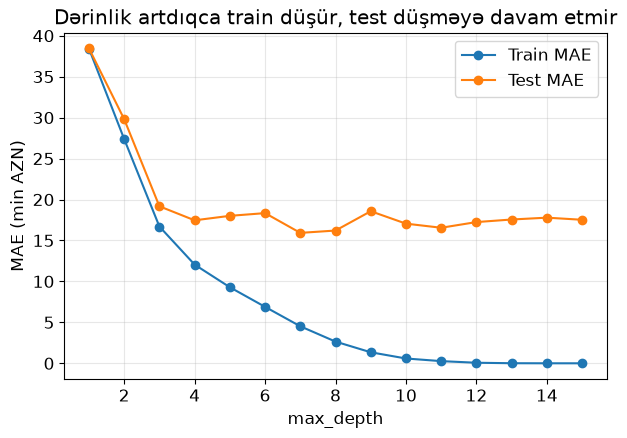

Ən kiçik test MAE dərinlik = 7
Dərinlik 15: train MAE = 0.00,  test MAE = 17.52


In [29]:
derinlikler = list(range(1, 16))
train_mae, test_mae = [], []

for d in derinlikler:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    train_mae.append(mean_absolute_error(y_train, model.predict(X_train)))
    test_mae.append(mean_absolute_error(y_test, model.predict(X_test)))

plt.plot(derinlikler, train_mae, marker="o", label="Train MAE")
plt.plot(derinlikler, test_mae, marker="o", label="Test MAE")
plt.xlabel("max_depth")
plt.ylabel("MAE (min AZN)")
plt.title("Dərinlik artdıqca train düşür, test düşməyə davam etmir")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

en_yaxsi = derinlikler[int(np.argmin(test_mae))]
print(f"Ən kiçik test MAE dərinlik = {en_yaxsi}")
print(f"Dərinlik 15: train MAE = {train_mae[-1]:.2f},  test MAE = {test_mae[-1]:.2f}")

Mavi xətt train-dir. Dərinlik artdıqca 0-a enir. Dərinlik 15-də train MAE **0**: ağac gördüyü 300 mənzili əzbərləyib.

Narıncı xətt test-dir, görmədiyi 100 mənzil. Əvvəl enir, çünki bir sual azdır, üç-dörd sual qaydanı daha yaxşı tutur. Sonra eniş dayanır və xətt 16–19 arasında tərpənir. Yeni mənzillər köhnə leaf-lərin təsadüfi qiymətinə düşür.

Dərinlik 15-də test MAE təxminən **18**-dir. Train 0, test 18. Bu boşluq overfitting-dir.

Ən aşağı narıncı nöqtə mütləq dərinlik 15 olmur. Bu data-da kod **7** deyir. Orada da train MAE təxminən 5, test təxminən 16-dır. Boşluq qalır. Dərinlik 3 test-də təxminən **19** verir və ağacı hələ oxumaq olur.

Bir azdan Random Forest testi təxminən **13**-ə, XGBoost isə **11**-ə endirəcək. Tək ağacın ən uğurlu dərinliyi belə onları keçmir.

> 💡 Ağacı dayandırmaq üçün `max_depth` və ya `min_samples_leaf` veririk. `min_samples_leaf = 2` o deməkdir ki, leaf-də ən azı 2 mənzil qalsın, tək bir elanın qiyməti qayda sayılmasın. Xətt üçün alpha nə idisə, ağac üçün bu parametrlər odur.


# 🅲 Hissə 3. Random Forest

## 1️⃣3️⃣ Bir ağac əvəzinə meşə

Bir dərin ağac bəzi leaf-lərdə 1–2 mənzili əzbərləyir. O leaf-ə düşən yeni mənzil təsadüfi qiymət alır.

**Random Forest** çoxlu ağac öyrədir. Regression-da yeni mənzil üçün hər ağac bir qiymət deyir, model isə onların **ortasını** götürür.

Niyə orta kömək edir? Tutaq ki, əsl qiymət 200-dür.

- 1-ci ağac noise ucbatından 260 deyir
- 2-ci ağac 150 deyir
- 3-cü ağac 210 deyir

Biri bahalaşdırır, biri ucuzlaşdırır. Üçünün ortası 207-dir, 260-dan yaxşıdır. Ağaclar eyni səhvi eyni yerdə etsə, orta kömək etməz. Ona görə ağacları bir-birindən fərqli öyrədirik. İki yol var:

1. **Bootstrap.** Hər ağac train-in eyni nüsxəsini görmür. 300 mənzildən 300 dəfə təsadüfi seçirik və seçilmiş mənzili geriyə qoyuruq. Bəzi mənzil iki dəfə düşür, bəzisi heç düşmür. Hər ağacın "gördüyü imtahan" bir az başqadır.
2. **Təsadüfi sütunlar.** Hər sualda ağac 8 sütunun hamısına baxmır. Biz yarısını veririk: `max_features = 0.5`. Bir ağac əvvəl məsafəyə, o biri əvvəl sahəyə baxa bilər. Hamı eyni birinci sualı versə, ağaclar bir-birinin surəti olar və ortanın mənası qalmaz.

Nəticə: hər ağac noise-u başqa yerdə əzbərləyir. Orta götürəndə bu təsadüfi səhvlər bir-birini azaldır, ümumi qayda qalır.


In [34]:
# Bootstrap-u 10 sətir üzərində görək
secim = np.random.default_rng(0).choice(10, size=10, replace=True)
print("Seçilən indekslər:", secim.tolist())
tekrar = sorted({int(v) for v in secim[pd.Series(secim).duplicated()]})
print("Təkrarlananlar   :", tekrar)
print("Heç düşməyənlər  :", [i for i in range(10) if i not in set(secim.tolist())])

Seçilən indekslər: [8, 6, 5, 2, 3, 0, 0, 0, 1, 8]
Təkrarlananlar   : [0, 8]
Heç düşməyənlər  : [4, 7, 9]


10 mənzildən 10 kart çəkdik və hər dəfə kartı destəyə qaytardıq. Çıxışda bəzi nömrə iki dəfədir (0 və 8), bəzi nömrə heç yoxdur (4, 7, 9).




train MAE = 6.57
test  MAE = 13.00
test  R²  = 0.925


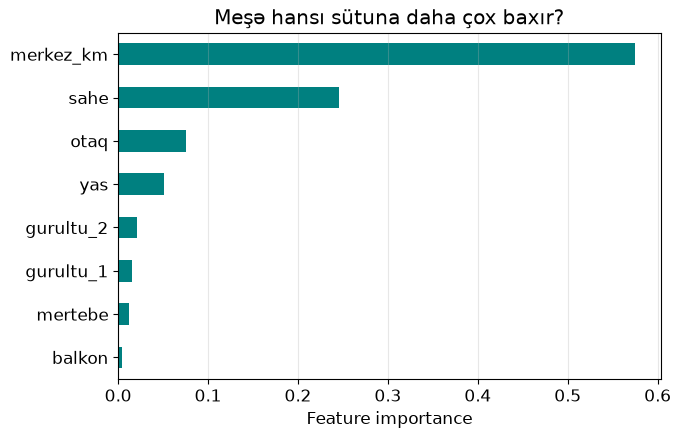

In [35]:
mese = RandomForestRegressor(
    n_estimators=300,      # 300 ağac
    max_features=0.5,      # hər bölünmədə sütunların yarısı
    min_samples_leaf=2,    # yarpaqda ən azı 2 mənzil, tək sətri əzbərləməsin
    random_state=42,
    n_jobs=1,
)
mese.fit(X_train, y_train)

print(f"train MAE = {mean_absolute_error(y_train, mese.predict(X_train)):.2f}")
print(f"test  MAE = {mean_absolute_error(y_test, mese.predict(X_test)):.2f}")
print(f"test  R²  = {r2_score(y_test, mese.predict(X_test)):.3f}")

onem = pd.Series(mese.feature_importances_, index=features).sort_values()
onem.plot(kind="barh", color="teal")
plt.xlabel("Feature importance")
plt.title("Meşə hansı sütuna daha çox baxır?")
plt.grid(alpha=0.3, axis="x")
plt.show()

Test MAE təxminən **13 min AZN**-dir. Dərinliyi 3 olan tək ağacda təxminən 19 idi. Xətti modellərdə təxminən 22 idi.

**Feature importance** sütunun payıdır: ağaclar bölünəndə bu sütun error-u nə qədər azaldıb. Birinci **mərkəzə məsafə**, ikinci **sahə**. Qrafikdəki rəng və ağacın ilk sualı ilə eyni nəticə.

`gurultu` sütunlarının payı kiçikdir, amma ən sonda deyillər. Mərtəbə və balkonun təsiri məsafədən zəifdir, ona görə onların payı da azdır. Lasso noise sütununu tam 0 yazmışdı. Meşə isə "əsas siqnal məsafə və sahədir" deyir, qalanına kiçik pay saxlayır. 0 ilə kiçik pay eyni hökm deyil: Lasso sütunu atır, meşə onu zəif sayır.

Tək ağacın şəklini çəkib "model belə qərar verdi" demək asandır. 300 ağacın ortasını belə oxumaq olmur. Dəqiqlik artır, izah isə bir cədvələ yığılır. İşdə hər ikisi lazım olanda dayaz ağacı izah üçün, meşəni isə prediction üçün saxlayırlar.


# 🅳 Hissə 4. Gradient Boosting

## 1️⃣4️⃣ Növbəti ağac qalan səhvi öyrənir

Random Forest-da ağaclar bir-birini görmür. Hamısı eyni vaxtda öyrənir, sonda orta götürülür.

**Gradient Boosting** başqa cür işləyir. Ağaclar növbə ilə gəlir. Birinci ağac qiyməti təxmin edir. İkinci ağac qiyməti yox, **qalan səhvi** öyrənir. Üçüncü ağac hələ də qalan səhvi öyrənir.

Bunu redaktə kimi düşünün. İlk mətn kobuddur. Redaktor kənara yazır: "burada 40 min baha demisən, burada 30 min ucuz." Müəllif bütün mətni atıb yenidən yazmır. Yalnız həmin düzəlişləri kiçik bir əlavə ilə bağlayır. Bir neçə belə əlavədən sonra mətn yaxınlaşır.

Addımlar:

1. İlk prediction sadədir. Çox vaxt bütün mənzillərə **orta qiymət** deyirik.
2. **Residual** = real qiymət − indiki prediction. Bu, hələ düzəlməmiş səhvdir. Model 150 deyibsə, real 100-dürsə, residual = −50: "50 min baha demisən."
3. Kiçik bir ağac bu residual-ları öyrənir. Yəni target artıq qiymət deyil, səhvdir.
4. Yeni prediction = köhnə prediction + **learning_rate** × ağacın dediyi düzəliş.
5. 2–4 təkrarlanır. `n_estimators` bu təkrarların sayıdır.

`learning_rate` düzəlişin neçə faizini qəbul etdiyimizdir. Ağac "40 min aşağı sal" deyirsə və learning rate 0.1-dirsə, biz yalnız 4 min aşağı salırıq. Qalanını növbəti ağaclar yavaş-yavaş bağlayır. Addım böyük olsa, düzəliş həddini aşır və model yenidən noise-u öyrənməyə başlayır.

"Gradient" sözü buradandır: squared error-un azaldığı istiqamət elə residual-dır. Bu gün törəmə hesablamırıq. Residual kifayətdir.

| | Random Forest | Gradient Boosting |
|---|---|---|
| Ağaclar | Eyni vaxtda, bir-birini görmür | Növbə ilə, hər biri əvvəlkinin səhvini görür |
| Hər ağac nəyi öyrənir? | Qiymətin özünü | Qalan residual-ı |
| Cavab necə birləşir? | Orta | Cəm: ilk təxmin + kiçik düzəlişlər |
| Əsas risk | Ağaclar çox dərin olarsa, hər biri əzbərləyir | learning rate böyük olarsa, düzəliş həddini aşır |


### 6 mənzillə 3 raund

Kitabxanadan əvvəl bunu 6 mənzildə əl ilə görək. Hər raundda **stump** öyrənirik: yalnız bir sual və iki leaf. Məsələn, "sahə 80-dən kiçikdirmi?" Sol leaf həmin tərəfin residual-larının ortasıdır, sağ leaf o biri tərəfin.

`learning_rate = 0.8` o deməkdir ki, ağacın dediyi düzəlişin 80%-ini qəbul edirik. 0.8 burada şəklin tez görünməsi üçündür. Əsl modeldə adətən 0.05 və ya 0.1 olur, ağac sayı isə daha çox olur.

| sahə | 40 | 55 | 70 | 90 | 110 | 130 |
|---|---|---|---|---|---|---|
| real qiymət | 80 | 95 | 120 | 160 | 190 | 230 |

Əsl qayda görünür: sahə artır, qiymət artır. Başlanğıc model bunu bilmir. Hamıya orta qiyməti deyir, təxminən **146**.


In [37]:
mini = pd.DataFrame({
    "sahe":   [40, 55, 70, 90, 110, 130],
    "qiymet": [80, 95, 120, 160, 190, 230],
})
sahe_m = mini["sahe"].to_numpy(float)
y_m = mini["qiymet"].to_numpy(float)

learning_rate = 0.8
prediction = np.full_like(y_m, y_m.mean())
tarix = [prediction.copy()]

def en_yaxsi_kotuk(sahe, residual):
    en_yaxsi = None
    for i in range(len(sahe) - 1):
        serhed = (sahe[i] + sahe[i + 1]) / 2
        sol = sahe <= serhed
        sag = ~sol
        sol_deyer = residual[sol].mean()
        sag_deyer = residual[sag].mean()
        texmin = np.where(sol, sol_deyer, sag_deyer)
        mse = np.mean((residual - texmin) ** 2)
        if en_yaxsi is None or mse < en_yaxsi[0]:
            en_yaxsi = (mse, serhed, sol_deyer, sag_deyer, texmin)
    return en_yaxsi

for raund in range(1, 4):
    residual = y_m - prediction
    _, serhed, sol_d, sag_d, texmin = en_yaxsi_kotuk(sahe_m, residual)
    prediction = prediction + learning_rate * texmin
    tarix.append(prediction.copy())
    print(
        f"Raund {raund}: sahə <= {serhed:.0f} olarsa {learning_rate * sol_d:+.1f}, "
        f"əks halda {learning_rate * sag_d:+.1f}"
    )

cedvel_boost = pd.DataFrame({"sahe": sahe_m.astype(int), "real": y_m.astype(int)})
for i, pred in enumerate(tarix):
    ad = "başlanğıc (orta)" if i == 0 else f"raund {i}"
    cedvel_boost[ad] = np.round(pred, 1)
cedvel_boost["son residual"] = np.round(y_m - prediction, 1)
cedvel_boost

Raund 1: sahə <= 80 olarsa -38.0, əks halda +38.0
Raund 2: sahə <= 120 olarsa -7.4, əks halda +36.9
Raund 3: sahə <= 62 olarsa -10.4, əks halda +5.2


,sahe,real,başlanğıc (orta),raund 1,raund 2,raund 3,son residual
0,40,80,145.8,107.8,100.4,90.1,-10.1
1,55,95,145.8,107.8,100.4,90.1,4.9
2,70,120,145.8,107.8,100.4,105.6,14.4
3,90,160,145.8,183.8,176.4,181.6,-21.6
4,110,190,145.8,183.8,176.4,181.6,8.4
5,130,230,145.8,183.8,220.8,225.9,4.1


In [38]:
mse_raund = [np.mean((y_m - pred) ** 2) for pred in tarix]
for i, mse in enumerate(mse_raund):
    ad = "başlanğıc" if i == 0 else f"raund {i}"
    print(f"{ad:12} MSE = {mse:7.1f}")

başlanğıc    MSE =  2803.5
raund 1      MSE =   637.5
raund 2      MSE =   228.3
raund 3      MSE =   147.8


Bir mənzili üç raund boyu izləyək. **40 kv.m**, real qiymət **80**.

- Başlanğıc: model 146 deyir. Residual = 80 − 146 = **−66**. Model 66 min baha deyib.
- Raund 1. Stump deyir: sahə 80 və daha kiçikdirsə, 38 çıx. 146 − 38 = **108**. Hələ 28 min bahadır.
- Raund 2. Kiçik mənzillərdən bir az da çıxır, prediction **100** olur.
- Raund 3. 40 kv.m yenə sol qrupa düşür, daha 10 çıxılır, prediction **90** olur.

80-ə doğru gedir: 146 → 108 → 100 → 90. Üç addımda bitməyib, amma səhv 66-dan 10-a enib.

İndi **130 kv.m**, real qiymət **230**. Başlanğıc yenə 146-dır, bu dəfə model 84 min ucuz deyib. Raund 1 ona 38 əlavə edir, 184 olur. Raund 2, böyük mənzillərə ayrıca əlavə, təxminən 221. Raund 3-dən sonra təxminən **226**. 230-a yaxındır.

MSE bütün mənzillər üzrə raunddan raunda düşür: təxminən 2800 → 640 → 230 → 150.

Hər mənzil hər addımda yaxşılaşmaya bilər. Biri düzəlir, qonşusu bir raundluq bir az pisləşə bilər, çünki stump bütün sol qrupa eyni rəqəmi yazır. Ona görə düzəlişi ehtiyatla, kiçik learning rate ilə qəbul etmək adətdir.

> Yeni prediction = köhnə prediction + learning_rate × (səhvi öyrənən kiçik ağac)


## 1️⃣5️⃣ XGBoost

**XGBoost** gradient boosting-in sürətli versiyasıdır. Ağacların çox mürəkkəb olmasına da cərimə yazır, yəni içinə regularization da qoyur. Cədvəl data-sında (qiymət, risk, satış) uzun müddət ən güclü alətlərdən biri olub.

Üç parametri yadda saxlayın:

| Parametr | Nə edir? | Bizim seçim |
|---|---|---|
| `n_estimators` | Neçə ağac, yəni neçə düzəliş raundu | 200 |
| `max_depth` | Hər ağac nə qədər dərin olsun. Boosting-də ağaclar kiçik saxlanılır, çünki hər biri yalnız qalan səhvi tutmalıdır | 3 |
| `learning_rate` | Hər düzəlişin neçə faizi qəbul olunsun | 0.1 |

`pip install xgboost` lazımdır. Mac-də `import` OpenMP xətası verərsə, əlavə olaraq `brew install libomp`.


In [40]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    n_jobs=1,
)
xgb.fit(X_train, y_train)

print(f"train MAE = {mean_absolute_error(y_train, xgb.predict(X_train)):.2f}")
print(f"test  MAE = {mean_absolute_error(y_test, xgb.predict(X_test)):.2f}")
print(f"test  R²  = {r2_score(y_test, xgb.predict(X_test)):.3f}")

train MAE = 4.10
test  MAE = 10.78
test  R²  = 0.953


### learning rate çox kiçik və ya çox böyük olanda

Eyni dərinlik, yalnız 50 ağac. Addımın ölçüsünü dəyişirik. 50 raund azdır, ona görə fərq tez görünür.


In [41]:
lr_setir = []
for lr in [0.01, 0.1, 0.5, 1.0]:
    model = XGBRegressor(
        n_estimators=50, max_depth=3, learning_rate=lr, random_state=42, n_jobs=1
    )
    model.fit(X_train, y_train)
    lr_setir.append({
        "learning_rate": lr,
        "train MAE": round(mean_absolute_error(y_train, model.predict(X_train)), 2),
        "test MAE": round(mean_absolute_error(y_test, model.predict(X_test)), 2),
        "test R²": round(r2_score(y_test, model.predict(X_test)), 3),
    })
pd.DataFrame(lr_setir)

,learning_rate,train MAE,test MAE,test R²
0,0.01,36.49,37.25,0.535
1,0.10,7.76,10.52,0.951
2,0.50,2.86,12.59,0.941
3,1.00,1.13,16.01,0.906


- **learning rate = 0.01, 50 ağac.** Hər düzəlişin yalnız 1%-i qəbul olunur. 50 belə addım modeli orta qiymətdən azca tərpədir. Test MAE təxminən 37, R² təxminən 0.5. Bu, underfitting-dir. Kiçik addım özü pis deyil, amma ona çox raund lazımdır. 50 raund çatmır.
- **learning rate = 0.1.** Bu qısa yoxlamada test ən sakit olanlardandır.
- **learning rate = 1.0.** Ağac "40 min düzəlt" deyirsə, 40 minin hamısını qəbul edirik. Train MAE 1-ə enir, model train-i yaxşı tutur. Test isə pisləşir. Addım böyükdür, model noise-u da düzəltməyə başlayır. Bu, yenidən overfitting-dir.

Əsas modelimizdə learning rate **0.1** və ağac sayı **200**-dür. Addım kiçikdir, raund isə kifayət qədərdir.


## 1️⃣6️⃣ Hamısını bir cədvəldə

Eyni 100 test mənzili. Metrikalar keçən dərsdən: MAE və R². Model seçəndə **test** sütununa baxırıq. Train sütunu isə əzbərləyib-əzbərləmədiyini göstərir.


In [ ]:
derin = DecisionTreeRegressor(max_depth=None, random_state=42)
derin.fit(X_train, y_train)

modeller = [
    ("Linear", linear, X_test_s),
    ("Ridge", ridge, X_test_s),
    ("Lasso", lasso, X_test_s),
    ("Ağac, dərinlik 3", agac, X_test),
    ("Ağac, limitsiz", derin, X_test),
    ("Random Forest", mese, X_test),
    ("XGBoost", xgb, X_test),
]

netice = []
for ad, model, X_te in modeller:
    # train tərəfi: scaler-li modellər X_train_s görüb, ağaclar X_train
    X_tr = X_train_s if X_te is X_test_s else X_train
    p_tr = model.predict(X_tr)
    p_te = model.predict(X_te)
    netice.append({
        "model": ad,
        "train MAE": round(mean_absolute_error(y_train, p_tr), 2),
        "test MAE": round(mean_absolute_error(y_test, p_te), 2),
        "train R²": round(r2_score(y_train, p_tr), 3),
        "test R²": round(r2_score(y_test, p_te), 3),
    })

netice = pd.DataFrame(netice).set_index("model")
netice

In [ ]:
netice["test MAE"].plot(kind="bar", color="steelblue", rot=30)
plt.ylabel("Test MAE (min AZN)")
plt.title("Kiçik olan yaxşıdır")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

### Bu cədvəl nə deyir?

`random_state = 42` ilə rəqəmlər belə çıxır. Sizdə də eyni olmalıdır.

| Model | Test MAE, təxminən | Niyə belədir? |
|---|---|---|
| Linear / Ridge / Lasso | **22** | Hamısı bir düz xətdir. Lasso noise sütununu silir, amma "mərkəzdə bir qayda, kənarda başqa qayda" fərqini yaratmır |
| Ağac, dərinlik 3 | **19** | Əvvəl məsafə, sonra sahə. Qutular oxunur, amma hər qutuda hələ geniş qiymət aralığı var |
| Ağac, limitsiz | **18** | Train R² = **1.00**. Test meşədən zəifdir. Əzbərləyib |
| Random Forest | **13** | 300 ağacın ortası təsadüfi leaf səhvlərini azaldır |
| XGBoost | **11** | 200 kiçik düzəliş qalan səhvi bağlayır. Bu cədvəldə ən kiçik test error |

Dərsin qərarı:

- Metrik həmişə test-də oxunur. Train gözəl görünə bilər və bu, sübut deyil.
- Sadə model pis olmaya bilər. Xətti modelin test R²-si təxminən 0.83-dür. Bu, zəif rəqəm deyil.
- Ən kiçik error bu data-da XGBoost-dadır.
- İzah lazımdırsa, dayaz ağac və ya Lasso daha rahatdır. Ağacın yolunu sözlə demək olur, 200 ağacın cəmini yox.


### Bir yeni mənzil, yeddi cavab

Bu elan train-də yoxdur, test-də də yoxdur. Model indi onu ilk dəfə görür.

Sahə 95 kv.m, 3 otaq, bina 6 illik, mərkəzə 2 km, 7-ci mərtəbə, balkon var. Noise sütunlarına qəsdən təsadüfi rəqəm yazırıq (`gurultu_1 = 2.5`). Yaxşı model bu rəqəmlərə həssas olmamalıdır.


In [ ]:
yeni = pd.DataFrame([{
    "sahe": 95,
    "otaq": 3,
    "yas": 6,
    "merkez_km": 2.0,
    "mertebe": 7,
    "balkon": 1,
    "gurultu_1": 2.5,
    "gurultu_2": -1.7,
}])

yeni_s = pd.DataFrame(scaler.transform(yeni), columns=features)

cavablar = {
    "Linear": linear.predict(yeni_s)[0],
    "Ridge": ridge.predict(yeni_s)[0],
    "Lasso": lasso.predict(yeni_s)[0],
    "Ağac d=3": agac.predict(yeni)[0],
    "Ağac limitsiz": derin.predict(yeni)[0],
    "Random Forest": mese.predict(yeni)[0],
    "XGBoost": xgb.predict(yeni)[0],
}
for ad, qiymet in cavablar.items():
    print(f"{ad:16} -> {qiymet:6.1f} min AZN")

Mənzil mərkəzə yaxındır, sahəsi ortadan böyükdür, bina nisbətən yenidir. Bahalı tərəf gözlənilir. Modellər təxminən 240 ilə 270 arasında deyir. Eyni ədəd deyillər:

- Xətt bir düsturdan hesablayır.
- Dərinliyi 3 olan ağac bir leaf-in ortasını deyir, ona görə rəqəm daha "dəyirmi" görünür (təxminən 270).
- Meşə və XGBoost çoxlu ağacın nəticəsidir, arada bir yerə düşür.

Praktikada iki güclü model, məsələn Random Forest və XGBoost, bir-birinə yaxın rəqəm deyirsə, prediction-a daha çox etibar etmək olur. Biri 150, o biri 300 deyirsə, əvvəl data-ya baxmaq lazımdır.

**Sual:** `gurultu_1`-i 2.5-dən −2.5-ə dəyişsək, Lasso-nun cavabı dəyişəcəkmi? Niyə? İpucu: Lasso cədvəlində bu sütunun `w`-si nə idi?


## 🧠 Dərsin yekunu

**Overfitting və regularization**

- Overfitting: model köhnə data-nı əzbərləyir. Train error kiçikdir, test error böyükdür.
- Underfitting: model həddindən artıq sadədir. Train də zəifdir, test də.
- Yeni Cost = MSE + alpha × cərimə(w)
- **Ridge (L2)** `w`-ləri kiçildir, tam 0 etmək məcburiyyətində deyil
- **Lasso (L1)** lazımsız sütunun `w`-sini tam 0 edir
- alpha çox böyük olanda underfitting olur
- Ridge və Lasso-dan əvvəl sütunları **StandardScaler** ilə eyni miqyasa gətirin. Scaler yalnız train-də fit olunur

**Decision Tree**

- Sual verir, iki qrupa bölür, yenidən sual verir. Leaf-də orta qiymət durur
- **Entropy** qrupun qarışıqlığıdır. 50/50 olanda 1, təmiz qrupda 0
- **Information gain** sualın entropy-ni nə qədər azaltdığıdır
- Qiymət ədəd olduğu üçün Housing ağacı entropy yox, **MSE** istifadə edir. Addımlar eynidir
- `max_depth` ağacı dayandırır. Limitsiz dərinlik train-i əzbərlədir

**Random Forest**

- Çox ağac. Hər biri bootstrap ilə başqa sətirlər görür və hər sualda sütunların bir hissəsinə baxır
- Regression cavabı = ağacların ortası
- Tək dərin ağacdan yaxşı test verir, çünki təsadüfi səhvlər ortada azalır

**Gradient Boosting və XGBoost**

- Ağaclar növbə ilə gəlir. Hər biri residual-ı, yəni qalan səhvi öyrənir
- Yeni prediction = köhnə prediction + learning_rate × yeni ağac
- Kiçik learning rate və kifayət qədər ağac. Böyük addım train-i əzbərlədir
- Bu Housing cədvəlində ən kiçik test MAE XGBoost-da oldu, təxminən 11 min AZN

### Nə vaxt hansı model?

| Vəziyyət | Ağlabatan seçim |
|---|---|
| Əlaqə düz xəttə yaxındır və modeli sözlə izah etmək lazımdır | Linear Regression. Lazımsız sütun varsa, Lasso |
| Qayda düz xətt deyil, amma "model niyə belə dedi?" sualına cavab lazımdır | Dayaz Decision Tree |
| Cədvəl data-sıdır və ən kiçik test error lazımdır | Random Forest və ya XGBoost |

### AI ilə əlaqə

Şəkil və mətndə bu gün neyron şəbəkələr öndədir. Cədvəl data-sında, yəni qiymət, risk, satış kimi sətir-sütun məsələlərində Random Forest və XGBoost hələ də gündəlik işin əsas alətləridir. Dərin şəbəkələrdəki weight decay isə bu günkü L2 cəriməsinin eyni fikridir: çəkilər hədsiz böyüməsin, model data-nı əzbərləməsin.


---
# ✍️ Sərbəst tapşırıq

> 🎓 İndiyə qədər kodu biz yazırdıq. İndi növbə sizdədir. Yuxarıdakı xanaları bir dəfə işlədin ki, `X_train`, `y_train`, `agac`, `scaler` yaddaşda olsun.

| Tapşırıq | Mövzu | Çətinlik | Harada? |
|---|---|---|---|
| 1 | Ridge alpha-nı özünüz yoxlayın | ⭐ | Dərsdə |
| 2 | Entropiya və gain funksiyası | ⭐⭐ | Dərsdə |
| 3 | Üç ağacın train/test-i | ⭐⭐ | Dərsdə |
| 4 | Dərinlik qrafikini özünüz çəkin | ⭐⭐⭐ | Ev tapşırığı |
| 5 | Ağacın yolunu sözlə yazın | ⭐⭐⭐ | Ev tapşırığı |
| 6 | learning_rate eksperimenti | ⭐⭐⭐ | Ev tapşırığı |
| 7 | Konseptual suallar | ⭐⭐ | Ev tapşırığı |

**Qaydalar:** hər `# TODO` yerini özünüz yazın. Axırdakı cavabları əvvəlcə açmayın.

## Tapşırıq 1 ⭐: Ridge böyük alpha-da sıfır olurmu?

Dərsdə Lasso-nun alpha cədvəlini gördük. İndi **Ridge** üçün eyni şeyi edin.

**Nə etməlisiniz:**
1. alpha = 0.1, 10 və 200 üçün `Ridge` öyrədin (`X_train_s` üzərində)
2. Hər alpha üçün 8 w-ni çap edin
3. Hər alpha üçün **test MAE** çap edin
4. Heç bir w tam 0 oldumu?

In [ ]:
# Tapşırıq 1
for alpha in [0.1, 10, 200]:
    # TODO: Ridge modeli yaradın, X_train_s üzərində öyrədin
    # TODO: w-ləri və test MAE-ni çap edin
    pass

✏️ **Sual:** alpha 200-də test niyə pisləşir? Ridge-in w-ləri Lasso kimi tam 0 olurmu? `gurultu` sütunlarına baxın.

**Cavabınız:** *(buraya yazın)*

## Tapşırıq 2 ⭐⭐: Entropiyanı sıfırdan yazın

Dərsdəki funksiyalara baxmadan yazmağa çalışın. `numpy` sərbəstdir.

| Funksiya | Nə qaytarsın |
|---|---|
| `my_entropiya(saylar)` | H. `saylar` məsələn `[3, 1]` |
| `my_gain(parent, sol, sag)` | information gain |

In [ ]:
# Tapşırıq 2
def my_entropiya(saylar):
    # TODO
    return None

def my_gain(parent, sol, sag):
    # TODO
    return None

In [ ]:
# ✅ Yoxlama xanası (dəyişməyin)
yoxlamalar = [
    ("H 50/50", my_entropiya([4, 4]), 1.0),
    ("H təmiz", my_entropiya([5, 0]), 0.0),
    ("Gain yaxşı", my_gain([4, 4], [3, 1], [1, 3]), information_gain([4, 4], [3, 1], [1, 3])),
    ("Gain pis", my_gain([4, 4], [2, 2], [2, 2]), 0.0),
]
for ad, sizin, dogru in yoxlamalar:
    if sizin is not None and np.isclose(sizin, dogru):
        print(f"✅ {ad}: düzgündür ({sizin:.3f})")
    else:
        print(f"❌ {ad}: sizin nəticə = {sizin}, olmalıdır ≈ {dogru:.3f}")

## Tapşırıq 3 ⭐⭐: Üç ağac

`max_depth` = 1, 3 və 20 olan üç `DecisionTreeRegressor` öyrədin. Hər biri üçün train MAE, test MAE və train R² çap edin.

Sonra bir cümlə yazın: hansı dərinlikdə train ilə test arasındakı boşluq ən böyükdür və bu nə deməkdir?

In [ ]:
# Tapşırıq 3
for d in [1, 3, 20]:
    # TODO
    pass

✏️ **Cavabınız:** *(buraya yazın)*

---
## 🏠 Ev tapşırığı

## Tapşırıq 4 ⭐⭐⭐: Dərinlik qrafiki

Dərsdəki qrafiki **özünüz**, dərs xanasına baxmadan çəkin.

1. `d` = 1, 2, ..., 12
2. Hər d üçün ağac öyrədin, train MAE və test MAE-ni siyahıya yığın
3. İki əyrini bir qrafikdə çəkin, oxların adı və legend olsun
4. Test MAE-si ən kiçik olan dərinliyi çap edin

✏️ Qrafikin altında yazın: train əyrisi niyə test əyrisindən ayrılır?

In [ ]:
# Tapşırıq 4
# TODO

## Tapşırıq 5 ⭐⭐⭐: Ağacın yolunu sözlə yazın

Dərsdəki dərinlik-3 ağacı (`agac`) açıq olsun. Aşağıdakı iki mənzil üçün:

1. Hansı suallardan keçdiyini **sözlə** yazın (hə / yox)
2. Yarpaqda gözlədiyiniz təxmini qiyməti yazın
3. Sonra `agac.predict` ilə yoxlayın. Yaxın oldumu?

| Mənzil | sahə | otaq | yaş | mərkəz, km | mərtəbə | balkon |
|---|---|---|---|---|---|---|
| A | 120 | 4 | 3 | 1.5 | 9 | 1 |
| B | 50 | 2 | 30 | 12 | 2 | 0 |

`gurultu` sütunlarına 0 yaza bilərsiniz. Dərinlik 3 olan bu ağac onlara baxmır, bunu importance-dan da görmək olar.

✏️ **Əlavə sual:** limitsiz ağac bu iki mənzil üçün dayaz ağacdan çox fərqli ədəd verə bilər. Hansına daha çox etibar edərdiniz? Niyə?

In [ ]:
# Tapşırıq 5
# TODO: iki mənzil üçün predict

## Tapşırıq 6 ⭐⭐⭐: Addımın ölçüsü

`XGBRegressor` ilə üç model öyrədin. Hamısında `max_depth=3`, `random_state=42`.

| Model | n_estimators | learning_rate |
|---|---|---|
| Sakit | 300 | 0.05 |
| Dərsdəki kimi | 200 | 0.1 |
| Tələsik | 40 | 1.0 |

Hər biri üçün train MAE və test MAE çap edin.

✏️ Hansı model train-də ən gözəldir? Hansı test-də? "Train-i ən kiçik olanı seçirəm" qaydası niyə səhvdir?

In [ ]:
# Tapşırıq 6
# TODO

## Tapşırıq 7 ⭐⭐: Konseptual suallar

Kod yazmadan, öz sözlərinizlə (hər biri 1–3 cümlə).

1. Overfitting ilə underfitting-i bir-birindən necə ayırırsınız? Hansı metrikaya baxırsınız?
2. Ridge ilə Lasso-nun cəriməsi necə fərqlənir? Hansı modeli "bu sütun lazım deyil" demək üçün seçərdiniz?
3. Niyə Lasso və Ridge-dən əvvəl StandardScaler lazımdır, qərar ağacından əvvəl isə yox?
4. Entropiya 0 nə deməkdir? Entropiya 1 nə deməkdir?
5. Housing ağacı niyə entropiya yox, MSE istifadə edir?
6. Random Forest-da bootstrap olmasa və hər ağac eyni train-i görsə, ortanın nə xeyri qalar?
7. Gradient Boosting-də yeni ağac qiyməti birbaşa öyrənmir. Bəs nəyi öyrənir? learning_rate bu cəmə necə girir?
8. Bizim cədvəldə XGBoost xətti modeldən yaxşı oldu. Elə bir məsələ düşünün ki, orada düz xətt ağacdan **daha doğru seçim** olsun.

**Cavablarınız:** *(buraya yazın)*

## 🎯 Özünüqiymətləndirmə

- [ ] Train metrikası ilə test metrikasının fərqini misalla danışa bilərəm
- [ ] L1 və L2 cəriməsini sözlə və qrafiklə izah edə bilərəm
- [ ] alpha böyüyəndə modelin niyə sadələşdiyini deyə bilərəm
- [ ] Entropiyanı 50/50 və təmiz qrup üçün hesablaya bilərəm
- [ ] Dərinliyi 3 olan ağacın bir yolunu barmaqla gəzə bilərəm
- [ ] Random Forest-un niyə tək ağacdan sakit olduğunu deyə bilərəm
- [ ] Boosting-in "qalan səhvi öyrənmək" cümləsini öz misalımla danışa bilərəm
- [ ] Model seçəndə test MAE-yə baxıram, train MAE-yə yox

> 🌟 Hamısını işarələdinizsə, cədvəl veriləni ilə işləyən modelin əsas ailəsini artıq əlinizdə tutursunuz: cəriməli xətt, ağac, meşə, boosting.

<details>
<summary><b>💡 Cavablar (yalnız cəhd etdikdən sonra açın!)</b></summary>

**Tapşırıq 1**

```python
for alpha in [0.1, 10, 200]:
    model = Ridge(alpha=alpha)
    model.fit(X_train_s, y_train)
    print("alpha =", alpha)
    print(pd.Series(model.coef_, index=features).round(3))
    pred = model.predict(X_test_s)
    print("test MAE =", round(mean_absolute_error(y_test, pred), 2))
    print("tam sıfır olan w sayı =", int(np.sum(np.abs(model.coef_) < 1e-8)))
```

Ridge-in `w`-ləri tam 0 olmur, alpha 200-də belə. Test MAE isə təxminən 22-dən 28-ə qalxır: cərimə artıq faydalı sütunları da əzir. `gurultu` sütunları kiçik qala bilər, amma Lasso-dakı kimi səliqə ilə sönmür. Bu, L2 ilə L1-in əsas fərqidir.

**Tapşırıq 2**

```python
def my_entropiya(saylar):
    saylar = np.asarray(saylar, dtype=float)
    p = saylar / saylar.sum()
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

def my_gain(parent, sol, sag):
    n = np.sum(parent)
    return (
        my_entropiya(parent)
        - np.sum(sol) / n * my_entropiya(sol)
        - np.sum(sag) / n * my_entropiya(sag)
    )
```

**Tapşırıq 3**

```python
for d in [1, 3, 20]:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    print(
        d,
        "train MAE", round(mean_absolute_error(y_train, model.predict(X_train)), 2),
        "test MAE", round(mean_absolute_error(y_test, model.predict(X_test)), 2),
        "train R²", round(r2_score(y_train, model.predict(X_train)), 3),
    )
```

Ən böyük boşluq dərinlik 20-dədir. Train MAE təxminən 0, test isə 17 civarındadır. Ağac train mənzillərini əzbərləyib, yeni mənzillərdə isə o qədər dəqiq deyil.

**Tapşırıq 4**

```python
derinlik = range(1, 13)
tr, te = [], []
for d in derinlik:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    tr.append(mean_absolute_error(y_train, model.predict(X_train)))
    te.append(mean_absolute_error(y_test, model.predict(X_test)))

plt.plot(list(derinlik), tr, marker="o", label="Train MAE")
plt.plot(list(derinlik), te, marker="o", label="Test MAE")
plt.xlabel("max_depth")
plt.ylabel("MAE (min AZN)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("Ən yaxşı dərinlik:", list(derinlik)[int(np.argmin(te))])
```

Train düşür, çünki ağac gördüyü mənzilləri get-gedə daha kiçik qutulara bölür və onların qiymətini əzbərləyir. Test eyni sürətlə düşmür, çünki yeni mənzil həmin kiçik qutunun təsadüfi ortasına düşür.

**Tapşırıq 5**

Ağacın sualları (`export_text` ilə eyni olmalıdır):

- A (120 kv.m, mərkəz 1.5 km): `merkez_km <= 4.4` hə, `sahe <= 93.2` yox, `sahe <= 127.6` hə. Leaf təxminən **270** min AZN.
- B (50 kv.m, mərkəz 12 km): birinci sual yox, `merkez_km <= 9` yox, `sahe <= 85` hə. Leaf təxminən **78** min AZN.

```python
A = pd.DataFrame([{
    "sahe": 120, "otaq": 4, "yas": 3, "merkez_km": 1.5,
    "mertebe": 9, "balkon": 1, "gurultu_1": 0, "gurultu_2": 0,
}])
B = pd.DataFrame([{
    "sahe": 50, "otaq": 2, "yas": 30, "merkez_km": 12,
    "mertebe": 2, "balkon": 0, "gurultu_1": 0, "gurultu_2": 0,
}])
print("A", round(agac.predict(A)[0], 1))
print("B", round(agac.predict(B)[0], 1))
```

Etibarı dayaz ağaca və ya meşəyə verin. Limitsiz ağacın bəzi leaf-ində 1–2 train mənzili qalır. Onların təsadüfi qiyməti yeni elana keçməməlidir.

**Tapşırıq 6**

```python
variantlar = [("sakit", 300, 0.05), ("ders", 200, 0.1), ("telesik", 40, 1.0)]
for ad, n_agac, lr in variantlar:
    model = XGBRegressor(
        n_estimators=n_agac, max_depth=3, learning_rate=lr,
        random_state=42, n_jobs=1,
    )
    model.fit(X_train, y_train)
    print(
        ad,
        "train", round(mean_absolute_error(y_train, model.predict(X_train)), 2),
        "test", round(mean_absolute_error(y_test, model.predict(X_test)), 2),
    )
```

Tələsik model (learning rate = 1) train-də çox gözəl görünür və test-də uduzur. Sakit model və dərsdəki model test-də yaxındır. Seçimi train MAE yox, test MAE verir.

**Tapşırıq 7 (qısa istiqamət)**

1. Hər ikisinə train və test birlikdə baxılır. Overfitting: train açıq-aydın yaxşıdır, test pisdir. Underfitting: hər ikisi zəifdir.
2. L2 `w`-nin kvadratıdır, L1 isə moduludur. Sütunu modeldən atmaq üçün Lasso seçilir, çünki `w`-ni tam 0 edə bilir.
3. Cərimə `w`-nin böyüklüyünə baxır. Vahidlər fərqli olanda böyük rəqəmli `w` səhvən cəzalanır. Ağacın `w`-si yoxdur, o, "sahə 80-dən böyükdür?" soruşur.
4. Entropy 0: qrup təmizdir, hamısı eyni sinifdədir. Entropy 1: iki sinif 50/50-dir, nəticəni bilmirik.
5. Target ədəddir, sinif deyil. Qrupun içində qiymətlər bir-birinə yaxındırmı, bunu MSE ölçür.
6. Ağaclar eyni olar. Orta da tək ağacın özü olar, səhvlər bir-birini azaltmaz.
7. Residual-ı öyrənir, yəni real qiymət minus indiki prediction. Yeni prediction = köhnə + learning_rate × ağacın düzəlişi.
8. Məsələn, qiymət həqiqətən sahə ilə düz mütənasibdirsə və sətir azdırsa. Keçən dərsin 10 mənzillik cədvəli belədir. Orada ağac əzbərləyər, düz xətt isə qaydanı deyər.

</details>
